# Day 6 NLP: Classify Text Sentiment
## SMS ham/spam text classification with TF-IDF and Logistic Regression

**Problem statement:** Classify Text Sentiment — Preprocess the text (lowercase, remove punctuation/stopwords, tokenize, stem or lemmatize), extract features using Bag-of-Words or TF-IDF, then train a text classification model (e.g. Naive Bayes or Logistic Regression) to predict the label. Report Accuracy and F1-score, and show the top 10 most important words per class.

**Dataset:** [SMS Spam Collection Dataset (Kaggle)](https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset).

**Label interpretation:** This dataset supplies **ham** (legitimate messages) and
**spam** labels. It does not supply positive/negative sentiment labels. We meet
the assignment's text-classification requirements by predicting the labels
actually present in the supplied dataset; we do not invent sentiment labels.

**Submission by:** Bhanupriyacn. Run every cell in order; all tables and figures
are included in the executed notebook.

**Required outputs:** text preprocessing (Section 3), training-only TF-IDF
matrices and supervised Logistic Regression (Section 5), held-out Accuracy/F1
(Section 6), and 10 model-derived word stems for each class (Section 7).

## 1. Workflow

1. Load the two useful columns, inspect missing values and remove exact duplicate messages.
2. Lowercase, remove punctuation, tokenize, remove English stopwords and apply Porter stemming.
3. Make an approximately 80/20, stratified group split that keeps identical processed messages together.
4. Fit TF-IDF on training messages only and train Logistic Regression.
5. Report held-out accuracy and F1, per-class metrics and a confusion matrix.
6. Extract the 10 strongest word coefficients for **each** class and plot them.

TF-IDF vocabulary and inverse document frequencies are learned only from the
training partition. Deterministic preprocessing may be used to create split
groups because it does not learn statistics from the dataset. Model parameters
are fixed before the test partition is evaluated.

In [1]:
import os
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")

import html
import hashlib
import io
import json
import platform
import re
import unicodedata
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nltk
import sklearn
from IPython.display import display, Markdown
from nltk.stem import PorterStemmer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from threadpoolctl import threadpool_limits

threadpool_limits(limits=1)
RANDOM_STATE = 42
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})
pd.set_option("display.max_colwidth", 90)
print(f"Python {platform.python_version()} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | nltk {nltk.__version__}")

Python 3.12.14 | pandas 3.0.6 | scikit-learn 1.9.1 | nltk 3.10.3


## 2. Load and inspect the SMS dataset

On Kaggle, attach the linked dataset; this loader finds `spam.csv` under
`/kaggle/input`. Locally it checks `data/sms_spam/spam.csv`, `data/spam.csv` and
`spam.csv` alongside the notebook or in its parent folder. As a fallback, it
downloads the public Kaggle archive when internet is available. No credentials
or NLTK corpus downloads are required.

The CSV uses `v1` for the label and `v2` for the message. The extra unnamed
columns are not features. `latin-1` decoding handles this source file.

In [2]:
cwd = Path.cwd()
candidates = []
if Path("/kaggle/input").exists():
    candidates.extend(sorted(Path("/kaggle/input").rglob("spam.csv")))
for base in (cwd, cwd.parent):
    candidates.extend([base / "data" / "sms_spam" / "spam.csv",
                       base / "data" / "spam.csv", base / "spam.csv"])
data_path = next((p for p in candidates if p.is_file()), None)
if data_path is None:
    archive_url = ("https://www.kaggle.com/api/v1/datasets/download/"
                   "uciml/sms-spam-collection-dataset")
    try:
        with urlopen(archive_url, timeout=60) as response:
            archive_bytes = response.read()
        with ZipFile(io.BytesIO(archive_bytes)) as archive:
            member = next(name for name in archive.namelist()
                          if Path(name).name == "spam.csv")
            folder = cwd / "data" / "sms_spam"
            folder.mkdir(parents=True, exist_ok=True)
            data_path = folder / "spam.csv"
            data_path.write_bytes(archive.read(member))
    except Exception as exc:
        raise RuntimeError("Attach the SMS Spam Collection Dataset on Kaggle "
                           "or place spam.csv in data/sms_spam locally.") from exc

raw = pd.read_csv(data_path, encoding="latin-1", usecols=["v1", "v2"])
raw = raw.rename(columns={"v1": "label", "v2": "text"})
raw["source_row"] = np.arange(len(raw))
raw_rows = len(raw)
print(f"Loaded {data_path.name}: {raw_rows} messages")
display(raw[["label", "text"]].head())
display(raw[["label", "text"]].isna().sum().rename("missing_values").to_frame())
display(raw["label"].value_counts().rename("messages").to_frame())

Loaded spam.csv: 5572 messages


,label,text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Ci..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


,missing_values
label,0
text,0


,messages
label,
ham,4825
spam,747


Missing rows removed: 0
Exact duplicate messages removed: 403
Unique raw messages retained: 5169


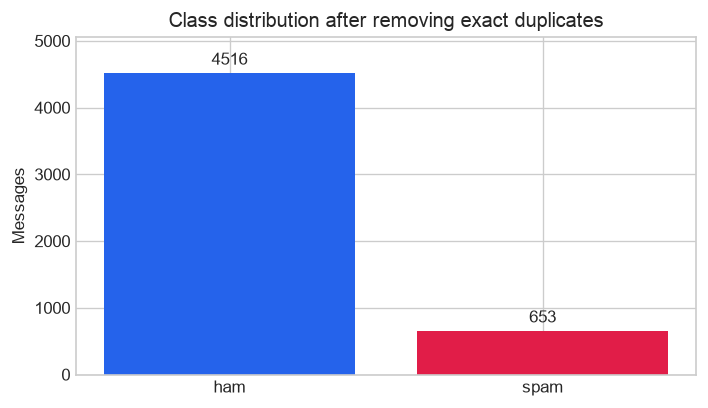

In [3]:
data = raw.dropna(subset=["label", "text"]).copy()
missing_rows_removed = raw_rows - len(data)
data["label"] = data["label"].str.strip().str.lower()
data["text"] = data["text"].astype(str)
assert set(data["label"]) == {"ham", "spam"}, "Unexpected class labels"
conflicting_raw = data.groupby("text")["label"].nunique()
assert not (conflicting_raw > 1).any(), "Identical raw texts have conflicting labels"
duplicates_removed = int(data.duplicated(subset=["text"]).sum())
data = data.drop_duplicates(subset=["text"]).reset_index(drop=True)
print(f"Missing rows removed: {missing_rows_removed}")
print(f"Exact duplicate messages removed: {duplicates_removed}")
print(f"Unique raw messages retained: {len(data)}")

class_counts = data["label"].value_counts().reindex(["ham", "spam"])
fig, ax = plt.subplots(figsize=(6, 3.5))
bars = ax.bar(class_counts.index, class_counts.values, color=["#2563eb", "#e11d48"])
ax.bar_label(bars, padding=3)
ax.set(ylabel="Messages", title="Class distribution after removing exact duplicates")
ax.set_ylim(0, class_counts.max() * 1.12)
fig.tight_layout()
plt.show()

## 3. Required text preprocessing

The processing function explicitly performs these steps:

- Normalize Unicode and decode HTML escapes, then convert to lowercase.
- Replace punctuation and other non-alphanumeric characters with spaces.
- Tokenize with a regular expression; keep English letters and digits.
- Remove scikit-learn's built-in English stopwords.
- Stem each remaining token with NLTK's PorterStemmer and join the stems.

Numbers are useful for spam detection, so they remain available as features.
Single-letter SMS tokens such as `u` and `k` are retained. The top-word report
excludes features made only of digits. Because the model uses stems, displayed
words may appear as `mobil`, `happi` or `repli` rather than their original forms.
PorterStemmer and the built-in stopword set work offline.

In [4]:
stemmer = PorterStemmer()
STOP_WORDS = set(ENGLISH_STOP_WORDS)

def preprocess_steps(text):
    normalized = html.unescape(unicodedata.normalize("NFKC", str(text))).lower()
    punctuation_removed = re.sub(r"[^a-z0-9\s]", " ", normalized)
    tokens = re.findall(r"[a-z0-9]+", punctuation_removed)
    without_stopwords = [token for token in tokens if token not in STOP_WORDS]
    stems = [stemmer.stem(token) for token in without_stopwords]
    return {"lowercase": normalized, "punctuation_removed": punctuation_removed,
            "tokens": tokens, "without_stopwords": without_stopwords,
            "stems": stems, "processed_text": " ".join(stems)}

def clean_text(text):
    return preprocess_steps(text)["processed_text"]

example = "Congratulations! You have WON a FREE mobile prize. Call us now!"
display(pd.DataFrame(preprocess_steps(example).items(), columns=["step", "result"]))
data["processed_text"] = data["text"].map(clean_text)
empty_count = int(data["processed_text"].eq("").sum())
print("Messages with no remaining tokens:", empty_count)
print("Distinct processed messages:", data["processed_text"].nunique())
display(data[["label", "text", "processed_text"]].head())

,step,result
0,lowercase,congratulations! you have won a free mobile prize. call us now!
1,punctuation_removed,congratulations you have won a free mobile prize call us now
2,tokens,"[congratulations, you, have, won, a, free, mobile, prize, call, us, now]"
3,without_stopwords,"[congratulations, won, free, mobile, prize]"
4,stems,"[congratul, won, free, mobil, prize]"
5,processed_text,congratul won free mobil prize


Messages with no remaining tokens: 13
Distinct processed messages: 5090


,label,text,processed_text
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Ci...",jurong point crazi avail bugi n great world la e buffet cine got amor wat
1,ham,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 t...,free entri 2 wkli comp win fa cup final tkt 21st 2005 text fa 87121 receiv entri quest...
3,ham,U dun say so early hor... U c already then say...,u dun say earli hor u c say
4,ham,"Nah I don't think he goes to usf, he lives around here though",nah don t think goe usf live


## 4. Hold out approximately 20% of messages

Different original messages can reduce to the same processed text. To prevent
those equivalents from crossing the training/test boundary, group messages by
processed text. Within each class, sort the unique groups by the SHA-256 hash of
the fixed seed and group text, then reserve the first 20% of groups (rounded up)
for testing. This creates a deterministic stratified group holdout that is
independent of scikit-learn's splitting implementation. Class proportions and
the test row count are approximate because groups cannot be split.

We retain messages whose processed text is empty; their TF-IDF vectors are all
zero and the classifier uses its intercept. All such messages stay in one split.

In [5]:
group_labels = data.groupby("processed_text")["label"].agg(["first", "nunique"])
assert group_labels["nunique"].eq(1).all(), "A processed-text group has conflicting labels"
test_groups = set()
for label in ["ham", "spam"]:
    groups = group_labels.index[group_labels["first"].eq(label)].tolist()
    ordered = sorted(groups, key=lambda value: (
        hashlib.sha256(f"{RANDOM_STATE}:{value}".encode("utf-8")).hexdigest(), value))
    test_groups.update(ordered[:int(np.ceil(0.20 * len(ordered)))])
is_test = data["processed_text"].isin(test_groups)
train = data.loc[~is_test].copy()
test = data.loc[is_test].copy()
assert set(train["processed_text"]).isdisjoint(set(test["processed_text"]))
assert set(train["source_row"]).isdisjoint(set(test["source_row"]))
assert len(train) + len(test) == len(data)
assert set(train["label"]) == set(test["label"]) == {"ham", "spam"}
split_table = pd.DataFrame({
    "train_count": train["label"].value_counts(),
    "test_count": test["label"].value_counts(),
    "train_pct": 100 * train["label"].value_counts(normalize=True),
    "test_pct": 100 * test["label"].value_counts(normalize=True),
}).reindex(["ham", "spam"])
display(split_table.round(2))
print(f"Training: {len(train)} | Test: {len(test)} ({100 * len(test) / len(data):.2f}%)")
print("Processed-text group overlap across train and test: 0")

,train_count,test_count,train_pct,test_pct
label,,,,
ham,3599,917,87.31,87.58
spam,523,130,12.69,12.42


Training: 4122 | Test: 1047 (20.26%)
Processed-text group overlap across train and test: 0


## 5. TF-IDF features and Logistic Regression

TF-IDF represents each message as a sparse vector of token weights. We use
unigrams, a minimum training document frequency of 2, maximum frequency of 98%,
sublinear term frequency and up to 8,000 vocabulary features. Messages are
cleaned before vectorization; new messages use the same `clean_text` function.

Logistic Regression uses `C=5`, `class_weight='balanced'`, `solver='liblinear'`
and `max_iter=1000`. These are fixed settings, not selected from the test scores.
Class weighting helps address the minority spam class. The decision threshold
is the model's default. A most-frequent-class baseline shows why high accuracy
alone can be misleading for this imbalanced dataset.

In [6]:
# Learn the vocabulary and IDF from training text only.
vectorizer = TfidfVectorizer(
    tokenizer=str.split, token_pattern=None, lowercase=False,
    ngram_range=(1, 1), min_df=2, max_df=0.98,
    max_features=8000, sublinear_tf=True)
X_train_tfidf = vectorizer.fit_transform(train["processed_text"])
X_test_tfidf = vectorizer.transform(test["processed_text"])

# Supervised classification: fit the text features against their true labels.
model = LogisticRegression(
    C=5.0, class_weight="balanced", solver="liblinear", max_iter=1000,
    random_state=RANDOM_STATE)
model.fit(X_train_tfidf, train["label"])
predicted = model.predict(X_test_tfidf)
classifier = model
assert list(classifier.classes_) == ["ham", "spam"]
print("Training TF-IDF matrix:", X_train_tfidf.shape)
print("Test TF-IDF matrix:", X_test_tfidf.shape)
print("Vocabulary was fitted on training messages only.")

baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(np.zeros((len(train), 1)), train["label"])
baseline_predicted = baseline.predict(np.zeros((len(test), 1)))

Training TF-IDF matrix: (4122, 2734)
Test TF-IDF matrix: (1047, 2734)
Vocabulary was fitted on training messages only.


## 6. Accuracy and F1-score on the held-out test set

Accuracy is the proportion of correct predictions. F1 balances precision and
recall. Report **spam F1** with spam as the positive class, **macro F1** which
weights both classes equally, and **weighted F1** which weights by class size.
The per-class report includes ham F1 as well. No test messages were used to fit
the model, vocabulary or IDF values.

,model,accuracy,f1_spam,f1_macro,f1_weighted,precision_spam,recall_spam
0,Most frequent baseline,0.8758,0.0000,0.4669,0.8179,0.0000,0.0000
1,TF-IDF + Logistic Regression,0.9838,0.9339,0.9623,0.9837,0.9449,0.9231


Held-out test accuracy: 0.9838
Held-out weighted F1-score: 0.9837
Held-out spam F1-score: 0.9339


,precision,recall,f1-score,support
ham,0.9891,0.9924,0.9907,917.0
spam,0.9449,0.9231,0.9339,130.0
macro avg,0.9670,0.9577,0.9623,1047.0
weighted avg,0.9836,0.9838,0.9837,1047.0


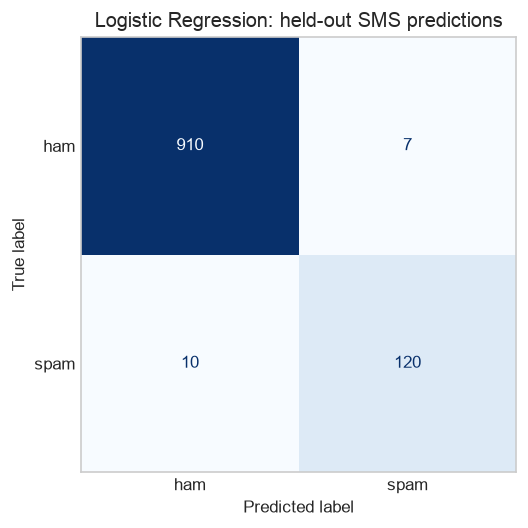

In [7]:
def metric_row(model_name, y_pred):
    return {
        "model": model_name,
        "accuracy": accuracy_score(test["label"], y_pred),
        "f1_spam": f1_score(test["label"], y_pred, pos_label="spam", zero_division=0),
        "f1_macro": f1_score(test["label"], y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(test["label"], y_pred, average="weighted", zero_division=0),
        "precision_spam": precision_score(test["label"], y_pred, pos_label="spam", zero_division=0),
        "recall_spam": recall_score(test["label"], y_pred, pos_label="spam", zero_division=0),
    }

metrics = pd.DataFrame([metric_row("Most frequent baseline", baseline_predicted),
                        metric_row("TF-IDF + Logistic Regression", predicted)])
display(metrics.round(4))
print(f"Held-out test accuracy: {accuracy_score(test['label'], predicted):.4f}")
print(f"Held-out weighted F1-score: {f1_score(test['label'], predicted, average='weighted'):.4f}")
print(f"Held-out spam F1-score: {f1_score(test['label'], predicted, pos_label='spam'):.4f}")
report_dict = classification_report(test["label"], predicted, labels=["ham", "spam"],
                                     output_dict=True, zero_division=0)
report = pd.DataFrame({label: report_dict[label]
                       for label in ["ham", "spam", "macro avg", "weighted avg"]}).T
display(report.round(4))

cm = confusion_matrix(test["label"], predicted, labels=["ham", "spam"])
artifact_dir = (Path("/kaggle/working/dev_week2_sms_outputs")
                if Path("/kaggle/working").exists()
                else Path.cwd().parent / "outputs" / "dev_week2_sms_results")
artifact_dir.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(cm, display_labels=["ham", "spam"]).plot(
    ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Logistic Regression: held-out SMS predictions")
ax.grid(False)
fig.tight_layout()
fig.savefig(artifact_dir / "confusion_matrix.png", dpi=160, bbox_inches="tight")
plt.show()

## 7. Top 10 most important words per class

For this binary Logistic Regression model, a positive coefficient favors
**spam**, and a negative coefficient favors **ham**, because the class order is
`['ham', 'spam']`. Rank words by their coefficients in the direction of each
class. This is model-specific association, not word frequency or a causal claim.

We report exactly 10 word tokens per class, excluding purely numeric features
from this word list. Numeric features still participate in model predictions.
The words shown are the stems used by the trained vectorizer. Both the
vocabulary and coefficients come from training data only.

**Top 10 words for ham**

,class,rank,word_stem,signed_spam_coefficient,class_support_strength
0,ham,1,k,-2.5029,2.5029
1,ham,2,ok,-2.4115,2.4115
2,ham,3,ll,-2.3152,2.3152
3,ham,4,home,-2.3052,2.3052
4,ham,5,da,-2.2283,2.2283
5,ham,6,u,-2.1383,2.1383
6,ham,7,got,-2.0888,2.0888
7,ham,8,hope,-2.0171,2.0171
8,ham,9,said,-2.0128,2.0128
9,ham,10,way,-1.9712,1.9712


**Top 10 words for spam**

,class,rank,word_stem,signed_spam_coefficient,class_support_strength
0,spam,1,uk,7.0812,7.0812
1,spam,2,txt,6.8080,6.8080
2,spam,3,servic,6.1694,6.1694
3,spam,4,150p,6.0972,6.0972
4,spam,5,mobil,5.9253,5.9253
5,spam,6,www,5.5403,5.5403
6,spam,7,claim,5.2102,5.2102
7,spam,8,repli,5.1084,5.1084
8,spam,9,text,4.9135,4.9135
9,spam,10,video,4.6792,4.6792


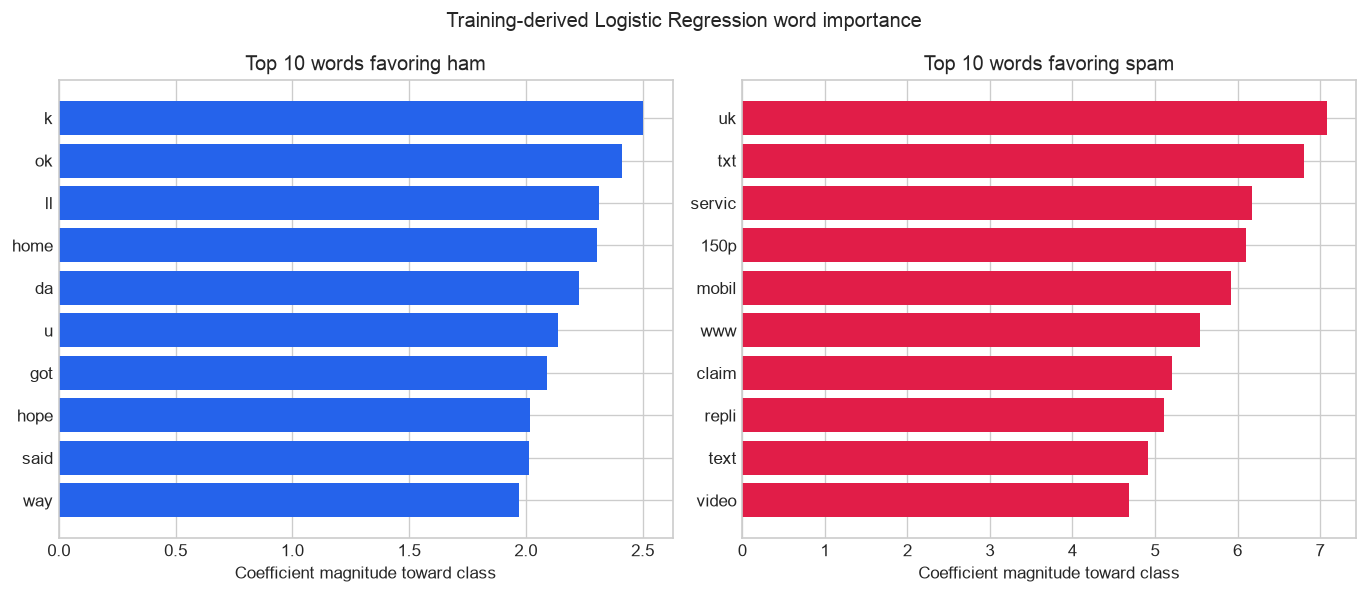

In [8]:
terms = vectorizer.get_feature_names_out()
coefficients = classifier.coef_[0]
is_word = np.array([bool(re.search(r"[a-z]", term)) for term in terms])
top_rows = []
for label, direction in [("ham", -1), ("spam", 1)]:
    supporting_indices = np.where(is_word & (direction * coefficients > 0))[0]
    strongest = supporting_indices[
        np.argsort(direction * coefficients[supporting_indices])[::-1][:10]]
    assert len(strongest) == 10
    for rank, index in enumerate(strongest, 1):
        top_rows.append({"class": label, "rank": rank, "word_stem": terms[index],
                         "signed_spam_coefficient": float(coefficients[index]),
                         "class_support_strength": float(direction * coefficients[index])})
top_words = pd.DataFrame(top_rows)
for label in ["ham", "spam"]:
    display(Markdown(f"**Top 10 words for {label}**"))
    display(top_words[top_words["class"] == label].reset_index(drop=True).round(4))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 5))
for ax, label, color in zip(axes, ["ham", "spam"], ["#2563eb", "#e11d48"]):
    words = top_words[top_words["class"] == label].sort_values("class_support_strength")
    ax.barh(words["word_stem"], words["class_support_strength"], color=color)
    ax.set_title(f"Top 10 words favoring {label}")
    ax.set_xlabel("Coefficient magnitude toward class")
fig.suptitle("Training-derived Logistic Regression word importance")
fig.tight_layout()
fig.savefig(artifact_dir / "top_10_words_per_class.png", dpi=160, bbox_inches="tight")
plt.show()

In [9]:
examples = ["Congratulations! Claim your free prize now. Call to win!",
            "Hi, are we still meeting at home later?"]
example_features = vectorizer.transform([clean_text(text) for text in examples])
example_predictions = model.predict(example_features)
example_probabilities = model.predict_proba(example_features)[:, 1]
display(pd.DataFrame({"message": examples,
                      "processed": [clean_text(text) for text in examples],
                      "predicted_label": example_predictions,
                      "spam_probability": example_probabilities}).round(4))

,message,processed,predicted_label,spam_probability
0,Congratulations! Claim your free prize now. Call to win!,congratul claim free prize win,spam,0.9914
1,"Hi, are we still meeting at home later?",hi meet home later,ham,0.0031


In [10]:
final_metrics = metrics.iloc[1].to_dict()
summary = {
    "assignment": "Day 6 NLP: Classify Text Sentiment (SMS ham/spam labels)",
    "dataset": "uciml/sms-spam-collection-dataset", "raw_messages": raw_rows,
    "duplicates_removed": duplicates_removed, "unique_messages": int(len(data)),
    "training_messages": int(len(train)), "test_messages": int(len(test)),
    "processed_group_overlap": 0, "vocabulary_size": int(len(terms)),
    "model": "TF-IDF + Logistic Regression",
    "accuracy": float(final_metrics["accuracy"]),
    "f1_spam": float(final_metrics["f1_spam"]),
    "f1_ham": float(report_dict["ham"]["f1-score"]),
    "f1_macro": float(final_metrics["f1_macro"]),
    "f1_weighted": float(final_metrics["f1_weighted"]),
    "spam_precision": float(final_metrics["precision_spam"]),
    "spam_recall": float(final_metrics["recall_spam"]),
    "confusion_matrix_label_order": ["ham", "spam"], "confusion_matrix": cm.tolist(),
    "top_10_words_per_class": {label: top_words[top_words["class"] == label]["word_stem"].tolist()
                               for label in ["ham", "spam"]},
}
display(Markdown(f"""
## 8. Findings and submission conclusion

The TF-IDF + Logistic Regression model achieves **{100 * summary['accuracy']:.2f}%
accuracy**, **{summary['f1_spam']:.4f} spam F1**, and **{summary['f1_macro']:.4f}
macro F1** on **{len(test)}** held-out messages. Ham F1 is
**{summary['f1_ham']:.4f}** and weighted F1 is **{summary['f1_weighted']:.4f}**.

We removed **{duplicates_removed}** exact duplicates and fitted on
**{len(train)}** training messages. The vocabulary contains **{len(terms)}**
features and was learned from the training set only. Identical processed
messages have **zero overlap** across the two partitions.

The confusion matrix shows **{int(cm[0, 1])}** legitimate messages flagged as
spam and **{int(cm[1, 0])}** spam messages missed. The table and bar charts
show all **10 most important word stems for each class**. These weights explain
associations in this fitted model; they do not guarantee that every message
containing a word belongs to that class.

The majority baseline's spam F1 is zero, so accuracy alone would conceal its
failure to detect spam. Reporting class-specific F1 and macro F1 makes that
imbalance visible. Results describe this fixed split of a small, historical SMS
corpus. Equivalent processed messages are grouped, but paraphrases can remain;
performance on new messages, languages or newer spam styles may differ.

The provided dataset supports ham/spam classification. Positive/negative
sentiment analysis would require a different, sentiment-labelled dataset.
"""))

metrics.to_csv(artifact_dir / "classification_metrics.csv", index=False)
report.to_csv(artifact_dir / "per_class_report.csv", index_label="class_or_average")
top_words.to_csv(artifact_dir / "top_10_words_per_class.csv", index=False)
split_table.to_csv(artifact_dir / "split_summary.csv", index_label="class")
pd.DataFrame({"source_row": test["source_row"].to_numpy(),
              "true_label": test["label"].to_numpy(), "predicted_label": predicted,
              "spam_probability": model.predict_proba(X_test_tfidf)[:, 1]})    .to_csv(artifact_dir / "test_predictions.csv", index=False)
(artifact_dir / "results_summary.json").write_text(json.dumps(summary, indent=2))
print("Exported evaluation tables, top words, test predictions and figures.")


## 8. Findings and submission conclusion

The TF-IDF + Logistic Regression model achieves **98.38%
accuracy**, **0.9339 spam F1**, and **0.9623
macro F1** on **1047** held-out messages. Ham F1 is
**0.9907** and weighted F1 is **0.9837**.

We removed **403** exact duplicates and fitted on
**4122** training messages. The vocabulary contains **2734**
features and was learned from the training set only. Identical processed
messages have **zero overlap** across the two partitions.

The confusion matrix shows **7** legitimate messages flagged as
spam and **10** spam messages missed. The table and bar charts
show all **10 most important word stems for each class**. These weights explain
associations in this fitted model; they do not guarantee that every message
containing a word belongs to that class.

The majority baseline's spam F1 is zero, so accuracy alone would conceal its
failure to detect spam. Reporting class-specific F1 and macro F1 makes that
imbalance visible. Results describe this fixed split of a small, historical SMS
corpus. Equivalent processed messages are grouped, but paraphrases can remain;
performance on new messages, languages or newer spam styles may differ.

The provided dataset supports ham/spam classification. Positive/negative
sentiment analysis would require a different, sentiment-labelled dataset.


Exported evaluation tables, top words, test predictions and figures.


## References

- [Kaggle SMS Spam Collection Dataset](https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset).
- [Original UCI SMS Spam Collection source and citation](https://archive.ics.uci.edu/dataset/228/sms+spam+collection).
- [NLTK PorterStemmer](https://www.nltk.org/api/nltk.stem.porter.html).
- [scikit-learn TF-IDF](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html).
- [Logistic Regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).
- [F1-score](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html).
- [Python hashlib: deterministic SHA-256 group ordering](https://docs.python.org/3/library/hashlib.html).